# Solar filament segmentation, end to end

This notebook walks through the whole pipeline on real images and reproduces the submitted predictions without
retraining. It loads the trained weights in `weights/`, runs the inference with them (about 20 minutes on one GPU;
results already in `work/` are reused) and calls the same functions as `run.py`. It needs the packages of
`requirements.txt` and the Kaggle data in `data/` (see the README), nothing else.

| Step | Code | What it does |
|---|---|---|
| 1. Detector | `filaments/detector.py` | four YOLO26s detectors, each trained on three of the four folds; boxes fused over eight views |
| 2. Masks | `filaments/segmenter.py` | a box-prompted U-Net turns every box into a mask probability |
| 3. Instances | `filaments/instances.py` | candidates of the four detectors are merged and selected without overlap |
| 4. Score | `filaments/metric.py` | Panoptic Quality against every annotator record |

Training takes about three hours on one RTX 4070 and is run from the command line (`reproduce.sh`, last section); this
notebook shows each step and runs the inference, the validation score and the test submission.

In [1]:
import contextlib
import io
import os
import shutil
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import cv2
import matplotlib.pyplot as plt
import numpy as np
from pycocotools import mask as cocomask

from filaments import data, detector, instances, metric, segmenter
from filaments.data import WORK
import run

import warnings
warnings.filterwarnings("ignore", message="IProgress not found")
plt.rcParams.update({"figure.dpi": 90, "font.size": 9})
COLORS = ["#e6194b", "#3cb44b", "#4363d8", "#f58231"]


def show(ax, image, window=None, title=None):
    # Grayscale image (or the window x0, y0, x1, y1 of it) without axes.
    x0, y0, x1, y1 = window or (0, 0, image.shape[1], image.shape[0])
    ax.imshow(image[y0:y1, x0:x1], cmap="gray", vmin=0, vmax=255)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlim(-0.5, x1 - x0 - 0.5); ax.set_ylim(y1 - y0 - 0.5, -0.5)
    if title:
        ax.set_title(title)


def outline(ax, rles, color, lw=1.0, window=None):
    # Outlines of full-canvas RLE masks, drawn in the coordinates of the displayed window.
    x0, y0 = window[:2] if window else (0, 0)
    for rle in rles:
        m, mx, my = data.decode_window(rle)
        for c in cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)[0]:
            c = c[:, 0] + [mx - x0, my - y0]
            ax.plot(*np.vstack([c, c[:1]]).T, color=color, lw=lw)


# The trained weights ship in weights/. The pipeline reads them from work/weights/, so they are copied there
# (weights already in work/weights/, e.g. from a run of reproduce.sh, are kept).
(WORK / "weights").mkdir(parents=True, exist_ok=True)
for path in sorted((ROOT / "weights").glob("*.pt")):
    if not (WORK / "weights" / path.name).exists():
        shutil.copy(path, WORK / "weights" / path.name)
print("weights:", sorted(p.name for p in (WORK / "weights").glob("*.pt")))


def infer(name, split, fold):
    # Boxes of detector `fold` on a split and the masks of mask model `name` for them (the `propose` and `segment`
    # steps of run.py), unless they are already in work/.
    proposals, masks = detector.proposals_path(fold, split), run.masks_path(name, split, fold)
    done = masks.exists()
    with contextlib.redirect_stdout(io.StringIO()):      # the two steps print absolute paths
        if not proposals.exists():
            detector.propose(fold, [split])
        if not done:
            segmenter.segment(name, proposals, masks, split == "test")
    print(f"detector {fold} + mask model '{name}' on {split}: {'reused' if done else 'computed'} {masks.name}")

weights: ['detector_fold0.pt', 'detector_fold1.pt', 'detector_fold2.pt', 'detector_fold3.pt', 'segmenter_final.pt', 'segmenter_validation.pt']


## 1. Data

2048 x 2048 GONG H-alpha images. Each training image carries one to three independent annotator records; the metric
treats every record as a separate ground truth. The folds group whole calendar months, so images taken a day apart never
end up on both sides of a split.

In [2]:
recs = data.records()
n_filaments = sum(len(r["rles"]) for rs in recs.values() for r in rs)
print(f"{len(recs)} training images, {sum(map(len, recs.values()))} annotator records, {n_filaments} filaments,",
      f"{len(data.test_stems())} test images")
print("images with 1 / 2 / 3 records:", np.bincount([len(v) for v in recs.values()])[1:].tolist())
for k in range(4):
    stems = data.fold_stems(k)
    print(f"fold {k}: {len(stems)} images, {sum(len(recs[s]) for s in stems)} records, {len({s[:6] for s in stems})} months")

707 training images, 1154 annotator records, 8199 filaments, 180 test images
images with 1 / 2 / 3 records: [411, 145, 151]
fold 0: 156 images, 248 records, 24 months
fold 1: 182 images, 310 records, 30 months
fold 2: 185 images, 304 records, 34 months
fold 3: 184 images, 292 records, 30 months


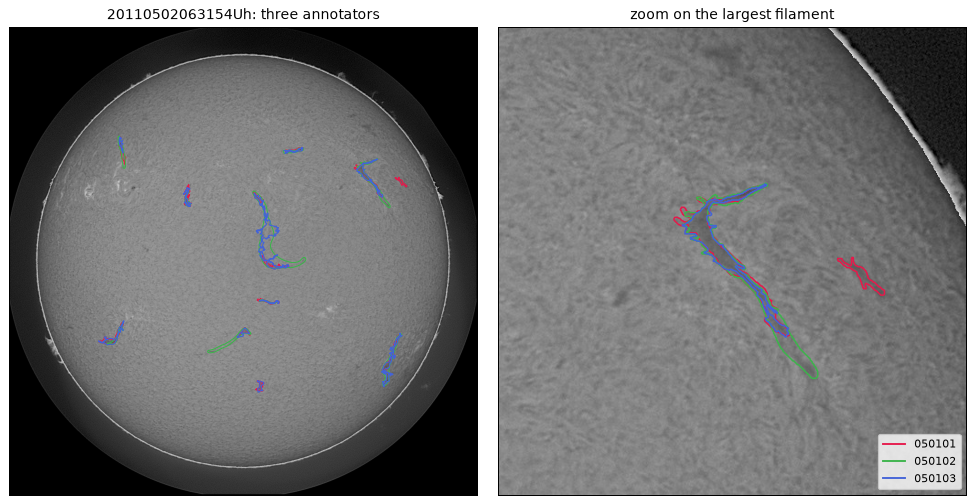

In [3]:
stem = next(s for s in data.fold_stems(0) if len(recs[s]) == 3 and 8 <= len(recs[s][0]["rles"]) <= 14)
image = data.load_image(stem)
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
show(axes[0], image, title=f"{stem}: three annotators")
for r, color in zip(recs[stem], COLORS):
    outline(axes[0], r["rles"], color, 0.8)
m, x0, y0 = data.decode_window(max(recs[stem][0]["rles"], key=cocomask.area))
cx, cy = x0 + m.shape[1] // 2, y0 + m.shape[0] // 2
window = (max(0, cx - 256), max(0, cy - 256), min(2048, cx + 256), min(2048, cy + 256))
show(axes[1], image, window, "zoom on the largest filament")
for r, color in zip(recs[stem], COLORS):
    outline(axes[1], r["rles"], color, 1.2, window)
axes[1].legend([plt.Line2D([], [], color=c) for c in COLORS[:3]], [r["id"][:6] for r in recs[stem]], loc="lower right")
plt.tight_layout()

## 2. Detector

Training samples are 1024 px tiles (3 x 3 per image, stride 512) at native resolution. Each (annotator record, tile)
pair is one sample, labelled with the polygons of that annotator's filaments inside the tile. The tiles and per-fold
datasets are written by `python run.py tiles`; `python run.py train-detector --fold K` fine-tunes the COCO-pretrained
YOLO26s for 12 epochs on the three other folds.

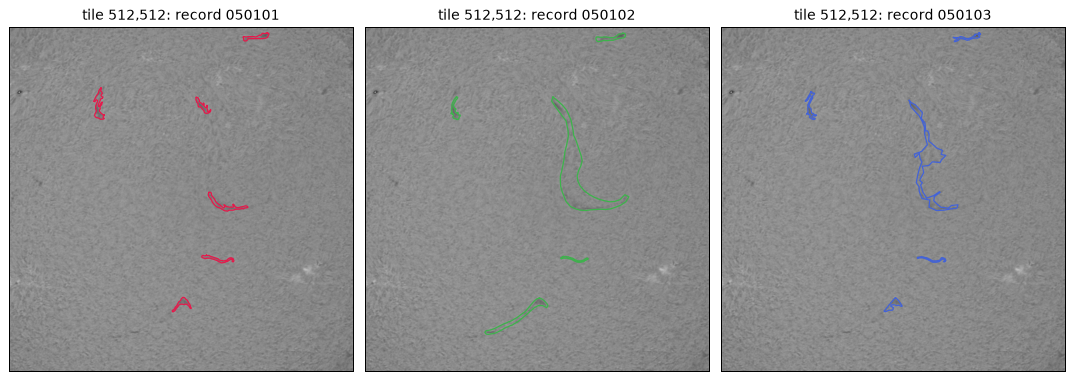

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
x0, y0 = 512, 512
for ax, r, color in zip(axes, recs[stem], COLORS):
    show(ax, image, (x0, y0, x0 + 1024, y0 + 1024), f"tile {x0},{y0}: record {r['id'][:6]}")
    for rle in r["rles"]:
        p = detector.tile_polygon(cocomask.decode(rle).astype(bool), x0, y0)
        if p is not None:
            ax.plot(*(p * 1024).T, color=color, lw=1)
plt.tight_layout()

At inference the full image goes through the detector at two input sizes (2048 and 1280 px) and four flips. The eight
box sets are fused with weighted box fusion: a fused box is the score-weighted mean of the boxes it absorbed, and its
score is the mean over the eight views, so a box found in every view keeps its confidence and a box found once loses it.
Here detector 0, which never saw fold 0, on the validation image above:

43 fused boxes; 13 with score >= 0.25


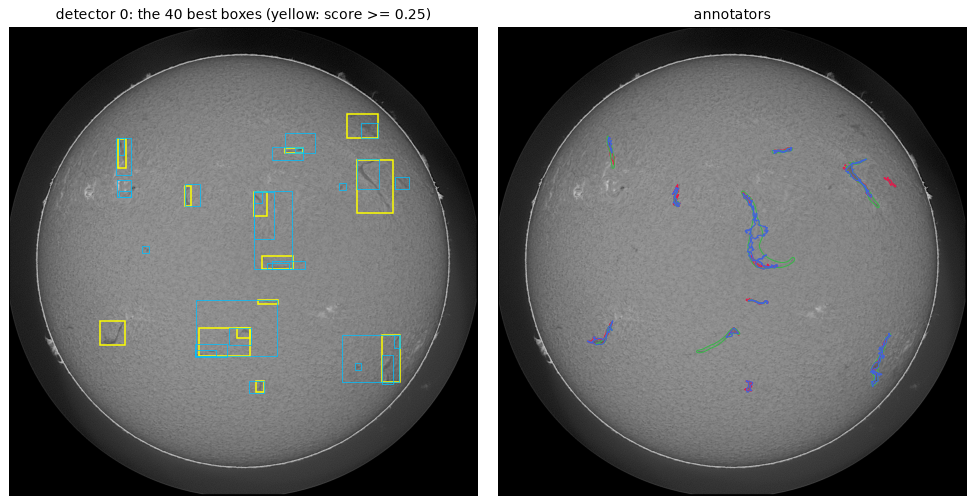

In [5]:
from ultralytics import YOLO

yolo = YOLO(str(detector.detector_path(0)))
boxes, scores = detector.detect(yolo, image)
print(f"{len(scores)} fused boxes; {np.sum(scores >= 0.25)} with score >= 0.25")
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
show(axes[0], image, title="detector 0: the 40 best boxes (yellow: score >= 0.25)")
for b, s in list(zip(boxes, scores))[:40]:
    axes[0].add_patch(plt.Rectangle(b[:2], b[2] - b[0], b[3] - b[1], fill=False, lw=1.2 if s >= 0.25 else 0.6,
                                    color="yellow" if s >= 0.25 else "deepskyblue"))
show(axes[1], image, title="annotators")
for r, color in zip(recs[stem], COLORS):
    outline(axes[1], r["rles"], color, 0.8)
plt.tight_layout()

## 3. Mask model

Each box becomes a square crop with 30% padding, letterboxed to 512 px. The U-Net (ResNet18 encoder) gets two channels:
the crop and a binary box prompt, and predicts the filament inside the box. Probabilities are averaged over four flips,
mapped back to the native crop, thresholded at 0.40, and the largest connected piece is kept.

The model is trained by `python run.py train-segmenter`: crops around every annotated filament, prompted with the
best-matching out-of-fold detector box (or the filament's own box if no detector box fits), plus two crops per image
around detector boxes that touch no annotation (empty target). Each epoch uses one random annotator record per image.

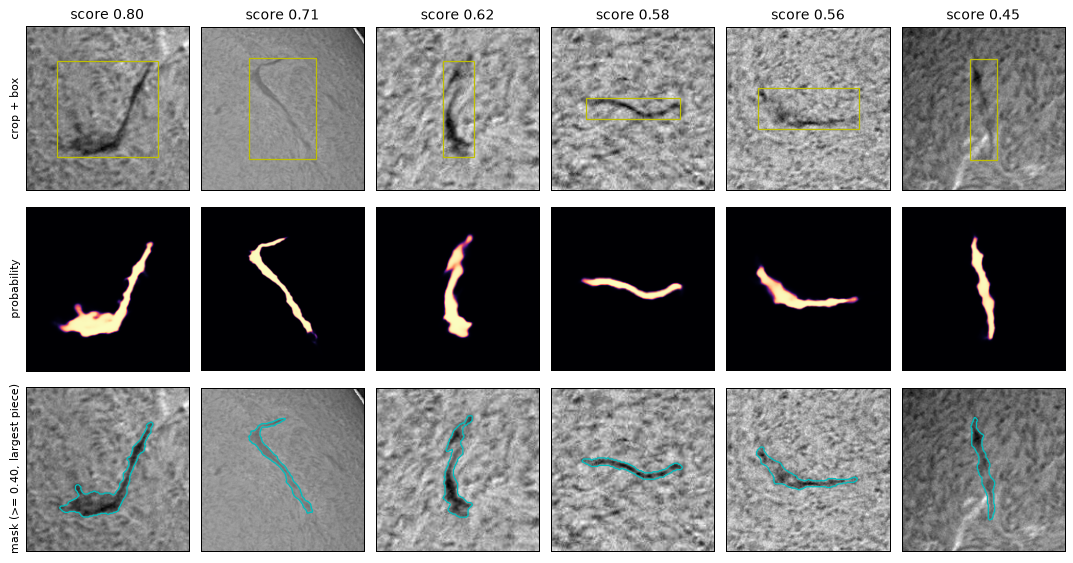

In [6]:
model = segmenter.load("final")
probs, crops, kept, geometry = segmenter.predict(model, image, boxes, scores)
fig, axes = plt.subplots(3, 6, figsize=(12, 6.4))
for j in range(6):
    x0, y0, x1, y1 = crops[j]
    crop = image[y0:y1, x0:x1]
    b = boxes[np.argsort(-scores, kind="stable")[j]] - [x0, y0, x0, y0]
    axes[0, j].imshow(crop, cmap="gray"); axes[0, j].add_patch(plt.Rectangle(b[:2], b[2] - b[0], b[3] - b[1], fill=False, color="y"))
    axes[0, j].set_title(f"score {kept[j]:.2f}")
    p = segmenter.restore(probs[j], geometry[j])
    axes[1, j].imshow(p, cmap="magma", vmin=0, vmax=1)
    mask = data.largest_component(p >= segmenter.THRESHOLD)
    axes[2, j].imshow(crop, cmap="gray")
    if mask is not None:
        axes[2, j].contour(mask, levels=[0.5], colors="c", linewidths=1)
    for ax in axes[:, j]:
        ax.set_xticks([]); ax.set_yticks([])
for row, label in enumerate(["crop + box", "probability", "mask (>= 0.40, largest piece)"]):
    axes[row, 0].set_ylabel(label)
plt.tight_layout()

## 4. From candidates to instances

The four detectors propose the same filament with slightly different boxes and masks. Candidates whose masks overlap
with IoU > 0.5 are one object; its score is the mean over the four detectors (a detector that missed it adds 0) and its
mask is that of its best member. Objects are then taken in score order: each one loses the pixels already taken, keeps
its largest remaining piece and is dropped if less than 150 px or 40% of it remains; pieces closer than 8 px are merged.
The cutoff is set so that the test set gets 6.2 instances per image, the density that scores best on validation.

The validation score below uses detector 0 alone with a mask model trained without fold 0 (`validation`), so nothing in
it has seen fold 0. The test submission uses all four detectors and the mask model trained on every image (`final`).

In [7]:
infer("validation", "heldout", 0)
val_stems = data.fold_stems(0)
val_objects = run.objects("validation", "heldout", [0], val_stems)
counts_by_density = {}
for density in (4.6, 5.4, 6.2, 7.0, 7.8):
    selection, cutoff = instances.select_at_density(val_objects, density)
    per_image = {s: metric.image_counts(recs[s], [rle for rle, _ in selection[s]]) for s in val_stems}
    counts_by_density[density] = per_image
    q = metric.panoptic_quality(sum(per_image.values()))
    print(f"{density:.1f} instances per image (cutoff {cutoff:.3f}): PQ {q['PQ']:.4f}  SQ {q['SQ']:.4f}  RQ {q['RQ']:.4f}")

detector 0 + mask model 'validation' on heldout: computed validation_heldout_fold0.jsonl


4.6 instances per image (cutoff 0.390): PQ 0.4444  SQ 0.6972  RQ 0.6374


5.4 instances per image (cutoff 0.308): PQ 0.4575  SQ 0.6939  RQ 0.6593


6.2 instances per image (cutoff 0.239): PQ 0.4618  SQ 0.6922  RQ 0.6673


7.0 instances per image (cutoff 0.178): PQ 0.4580  SQ 0.6913  RQ 0.6626


7.8 instances per image (cutoff 0.128): PQ 0.4508  SQ 0.6903  RQ 0.6530


In [8]:
per_image = counts_by_density[6.2]
rows = np.array([per_image[s] for s in val_stems])
rng = np.random.default_rng(0)
boot = [metric.panoptic_quality(rows[rng.integers(0, len(rows), len(rows))].sum(0))["PQ"] for _ in range(2000)]
print(f"fold 0 at 6.2 per image: PQ {metric.panoptic_quality(rows.sum(0))['PQ']:.4f}, "
      f"95% bootstrap interval over images {np.percentile(boot, 2.5):.4f} to {np.percentile(boot, 97.5):.4f}")
for n in (1, 2, 3):
    sel = [per_image[s] for s in val_stems if len(recs[s]) == n]
    print(f"  images with {n} record(s): {len(sel):3d} images, PQ {metric.panoptic_quality(sum(sel))['PQ']:.4f}")

fold 0 at 6.2 per image: PQ 0.4618, 95% bootstrap interval over images 0.4409 to 0.4826
  images with 1 record(s):  97 images, PQ 0.4608
  images with 2 record(s):  26 images, PQ 0.4694
  images with 3 record(s):  33 images, PQ 0.4595


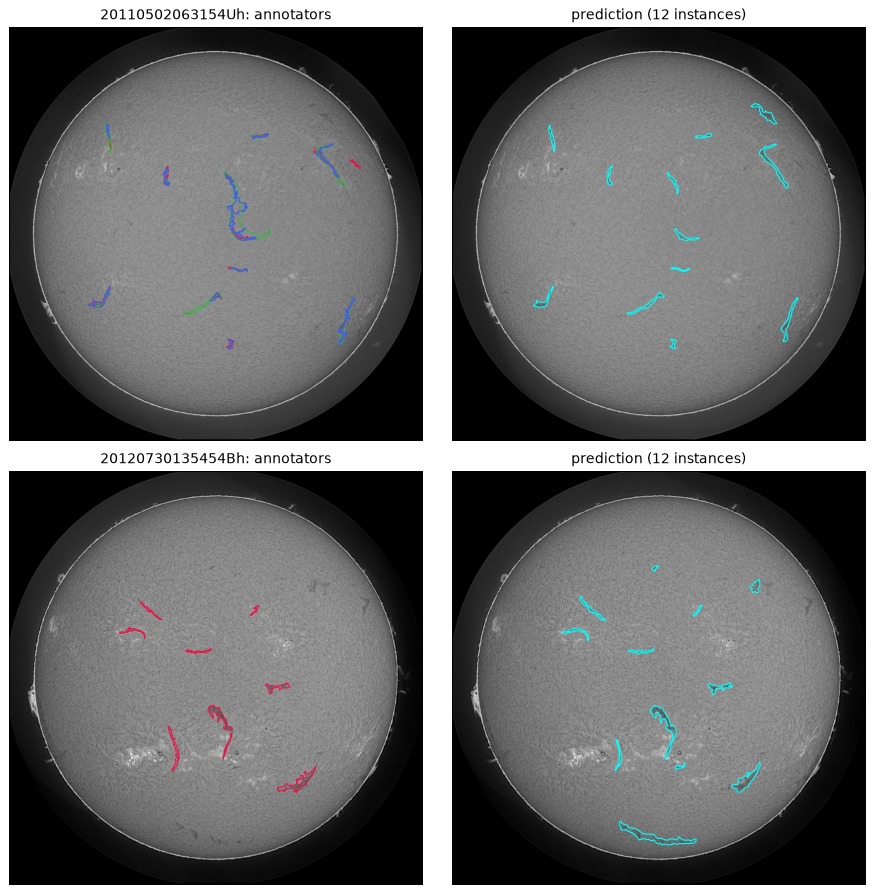

In [9]:
selection, _ = instances.select_at_density(val_objects, 6.2)
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for row, s in zip(axes, [stem, val_stems[40]]):
    img = data.load_image(s)
    show(row[0], img, title=f"{s}: annotators")
    for r, color in zip(recs[s], COLORS):
        outline(row[0], r["rles"], color, 0.8)
    show(row[1], img, title=f"prediction ({len(selection[s])} instances)")
    outline(row[1], [rle for rle, _ in selection[s]], "cyan", 0.8)
plt.tight_layout()

## 5. Test submission

Boxes of all four detectors on the test images (`python run.py propose`), masks of the final model
(`python run.py segment`), ensemble and selection (`python run.py submit`). The CSV has one row per instance:
`<image stem>_<rank>` and the COCO run-length encoding of its 2048 x 2048 mask.

In [10]:
for k in range(4):
    infer("final", "test", k)
test_stems = data.test_stems()
test_objects = run.objects("final", "test", range(4), test_stems)
selection, cutoff = instances.select_at_density(test_objects)
instances.write_submission(WORK / "submission.csv", selection)
n = sum(map(len, selection.values()))
print(f"{n} instances on {len(test_stems)} test images ({n / len(test_stems):.2f} per image), cutoff {cutoff:.4f}")
print(open(WORK / "submission.csv").read()[:300])

detector 0 + mask model 'final' on test: computed final_test_fold0.jsonl


detector 1 + mask model 'final' on test: computed final_test_fold1.jsonl


detector 2 + mask model 'final' on test: computed final_test_fold2.jsonl


detector 3 + mask model 'final' on test: computed final_test_fold3.jsonl


1116 instances on 180 test images (6.20 per image), cutoff 0.2515
filament_id,segmentation_rle
20110120105534Ch_1,WjPQ21no12N1O1O1O1O1O0O1000O1OO2000O01000000J600I8N01O10N2J6O00101L4O1NL5CUQN^O22hn1`0>1K410\OXOhQN3Ie0^n1YOhQN3Jd0^n1ZOcQNOL52;1@_n11`QNm0gn16O02O1OMmNZQNQ1gn1oNYQNo0in1ROWQNl0jn1TOVQN5O=ln1^OTQN43=jn1EWQN:jn1FVQN:jn1FVQN:jn1BRQNN5?hn1C^QN<an1E`QN:`n1


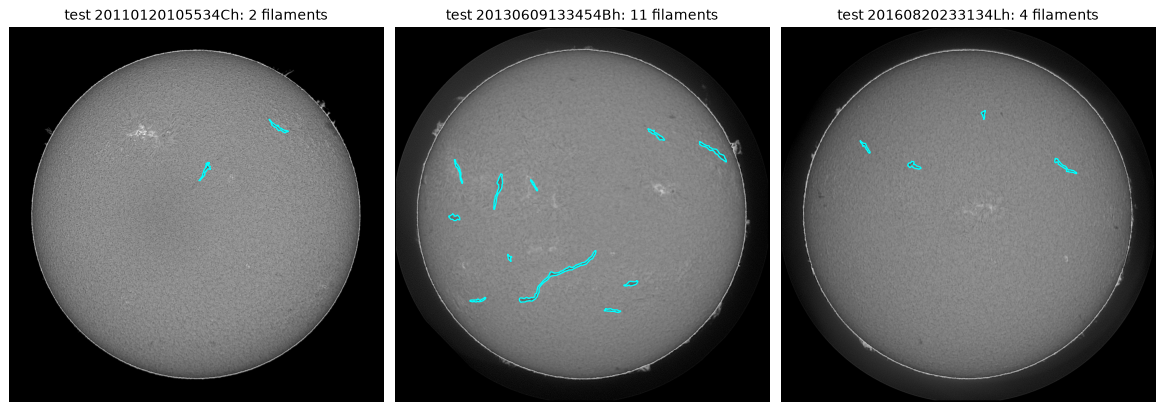

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, s in zip(axes, test_stems[::60]):
    show(ax, data.load_image(s, test=True), title=f"test {s}: {len(selection[s])} filaments")
    outline(ax, [rle for rle, _ in selection[s]], "cyan", 1.0)
plt.tight_layout()

## 6. Training from scratch

`reproduce.sh` runs every step from the Kaggle data to `work/submission.csv`:

```bash
python run.py tiles                                                 # detector training tiles (2 min, CPU)
for k in 0 1 2 3; do python run.py train-detector --fold $k; done   # four detectors (23 min each)
for k in 0 1 2 3; do python run.py propose --fold $k; done          # out-of-fold and test boxes (2 min each)
python run.py train-segmenter --name validation --exclude-fold 0    # validation mask model (25 min)
python run.py segment --name validation --split heldout --fold 0
python run.py evaluate --name validation                            # the fold-0 score above
python run.py train-segmenter --name final                          # final mask model (30 min)
for k in 0 1 2 3; do python run.py segment --name final --split test --fold $k; done
python run.py submit --name final                                   # work/submission.csv
```